Pobranie datasetu w środowisku Google Colab


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
# !wget -q https://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_HR.zip # High Resolution Images -> Train Data (HR images), 800 images for training
#!wget -q https://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_valid_HR.zip # High Resolution Images -> Validation Data (HR images), 100 images for testing

#!unzip -q DIV2K_train_HR.zip
#!unzip -q DIV2K_valid_HR.zip


In [5]:
import os

if not os.path.exists('DIV2K_train_HR'):
    !wget -q https://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_HR.zip
    !unzip -q DIV2K_train_HR.zip
if not os.path.exists('DIV2K_valid_HR'):
    !wget -q https://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_valid_HR.zip
    !unzip -q DIV2K_valid_HR.zip

In [7]:
import os, glob, random
import cv2
from collections import Counter
import matplotlib.pyplot as plt

Wyświetlamy 10 pierwszych obrazków z pobrango zbioru "train" wraz ze wskazaniem ich rozmiarów (wizualizacja)

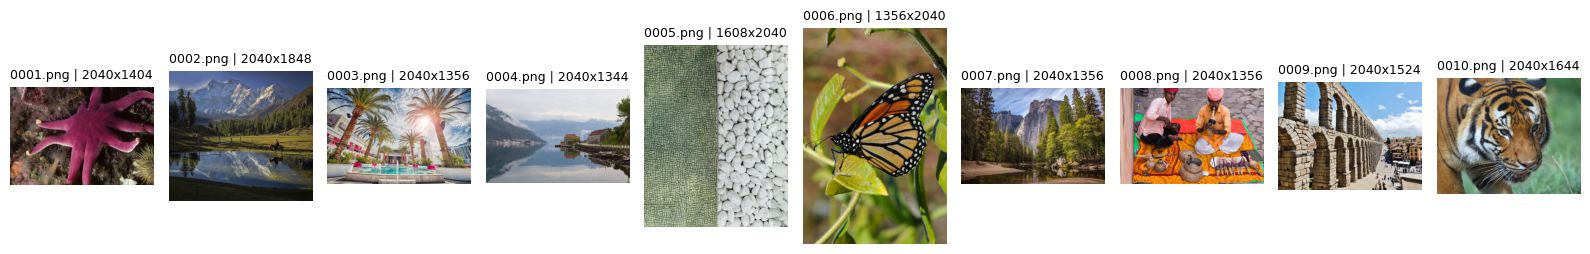

In [8]:
files = sorted(glob.glob('DIV2K_train_HR/*.png'))

fig, axis = plt.subplots(1, 10, figsize=(16, 10))
for i in range(10):
    img = cv2.cvtColor(cv2.imread(files[i]), cv2.COLOR_BGR2RGB)
    axis[i].imshow(img)
    axis[i].set_title(f'{files[i].split("/")[-1]} | {img.shape[1]}x{img.shape[0]}', fontsize=9)
    axis[i].axis('off')

plt.tight_layout()
plt.show()

Sprawdzamy jakie rozmiary obrazów są w zbiorach: trenigowym i walidacyjnym

In [9]:
for folder in ['DIV2K_train_HR', 'DIV2K_valid_HR']:
    paths = sorted(glob.glob(f'{folder}/*.png'))
    sizes = Counter()
    for p in paths:
        h, w = cv2.imread(p).shape[:2]
        sizes[(w, h)] += 1

    print(f'\n{folder}: {len(paths)} images, {len(sizes)} different sizes')
    for (w, h), count in sizes.most_common(5):
        print(f'  {w}x{h}: {count} images')


DIV2K_train_HR: 800 images, 94 different sizes
  2040x1356: 429 images
  1356x2040: 49 images
  2040x1536: 48 images
  2040x1368: 28 images
  2040x1152: 20 images

DIV2K_valid_HR: 100 images, 24 different sizes
  2040x1356: 53 images
  2040x1536: 13 images
  1356x2040: 7 images
  2040x1284: 3 images
  2040x1368: 3 images


Wyświelamy po 10 zdjeć w każdym ze zbiorów

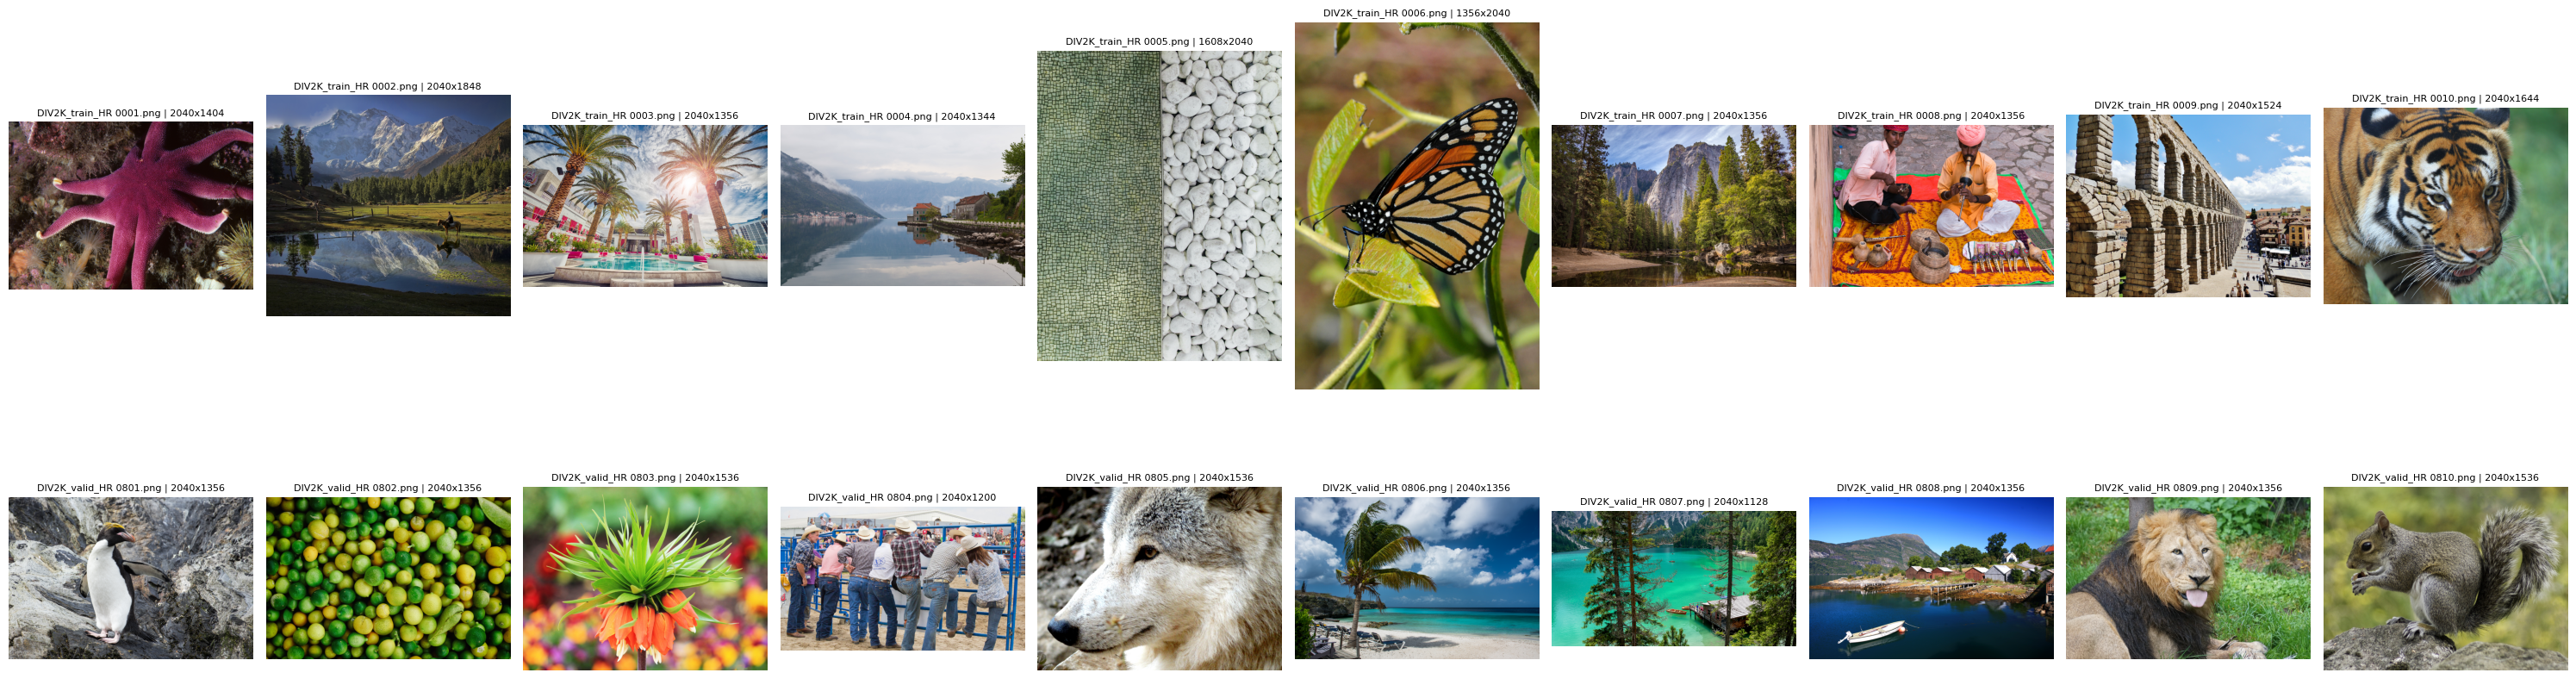

In [10]:
fig, axes = plt.subplots(2, 10, figsize=(30, 10))

for row, folder in enumerate(['DIV2K_train_HR', 'DIV2K_valid_HR']):
    paths = sorted(glob.glob(f'{folder}/*.png'))
    for col in range(10):
        img = cv2.cvtColor(cv2.imread(paths[col]), cv2.COLOR_BGR2RGB)  # OpenCV loads BGR, matplotlib needs RGB
        axes[row, col].imshow(img)
        axes[row, col].set_title(f'{folder} {paths[col].split("/")[-1]} | {img.shape[1]}x{img.shape[0]}', fontsize=8)
        axes[row, col].axis('off')

plt.tight_layout()
plt.show()

Jako, że w ramach trenowania i walidacji wyników eksperymentów, korzystamy z obrazów w rozdzielczości 256 × 256, to skalujemy obrazy - zmniejszamy go i wycinamy środek tak by skupić sie na głównej, centralnej części obrazów.

Do zmniejszania użyto cv2.INTER_AREA, która uśrednia piksele i daje mniej artefaktów przy zmniejszaniu obrazów.

In [14]:
SIZE = 256

def change_size(path):
    img = cv2.imread(path)                      # wczytanie obrazu
    h, w = img.shape[:2]
    scale = SIZE / min(h, w)                       # o ile zmniejszyć
    new_w, new_h = round(w * scale), round(h * scale)
    img = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_AREA)
    top = (new_h  - SIZE) // 2
    left = (new_w - SIZE) // 2
    return img[top:top + SIZE, left:left + SIZE] # wycięcie środka

Podział danych:
* train: 720 obrazów (DIV2K train bez 80 wylosowanych, seed=0)
* val: 80 obrazów (wylosowane z DIV2K train)
* test: 100 obrazów (cały DIV2K valid, ponieważ oryginalny zbiór testowy DIV2K nie ma publicznych obrazów HR)

In [12]:
train_all = sorted(glob.glob('DIV2K_train_HR/*.png'))
test_paths = sorted(glob.glob('DIV2K_valid_HR/*.png'))

random.seed(0)                    # stały seed, podział zawsze taki sam
random.shuffle(train_all)
val_paths = train_all[:80]
train_paths = train_all[80:]

output = '/content/drive/MyDrive/sigk/data256'

def save(paths, folder):
    os.makedirs(f'{output}/{folder}', exist_ok=True)
    for s in paths:
        name = os.path.basename(s)
        cv2.imwrite(f'{output}/{folder}/{name}', change_size(s))
    print(folder, len(paths))

save(train_paths, 'train')
save(val_paths, 'val')
save(test_paths, 'test')

train 720
val 80
test 100


Wyświetlamy przeskalowane obrazy z każdego z 3 zbiorów (treningowy, walidacyjny, testowy) - widać, że są kwadratami 256 x 256

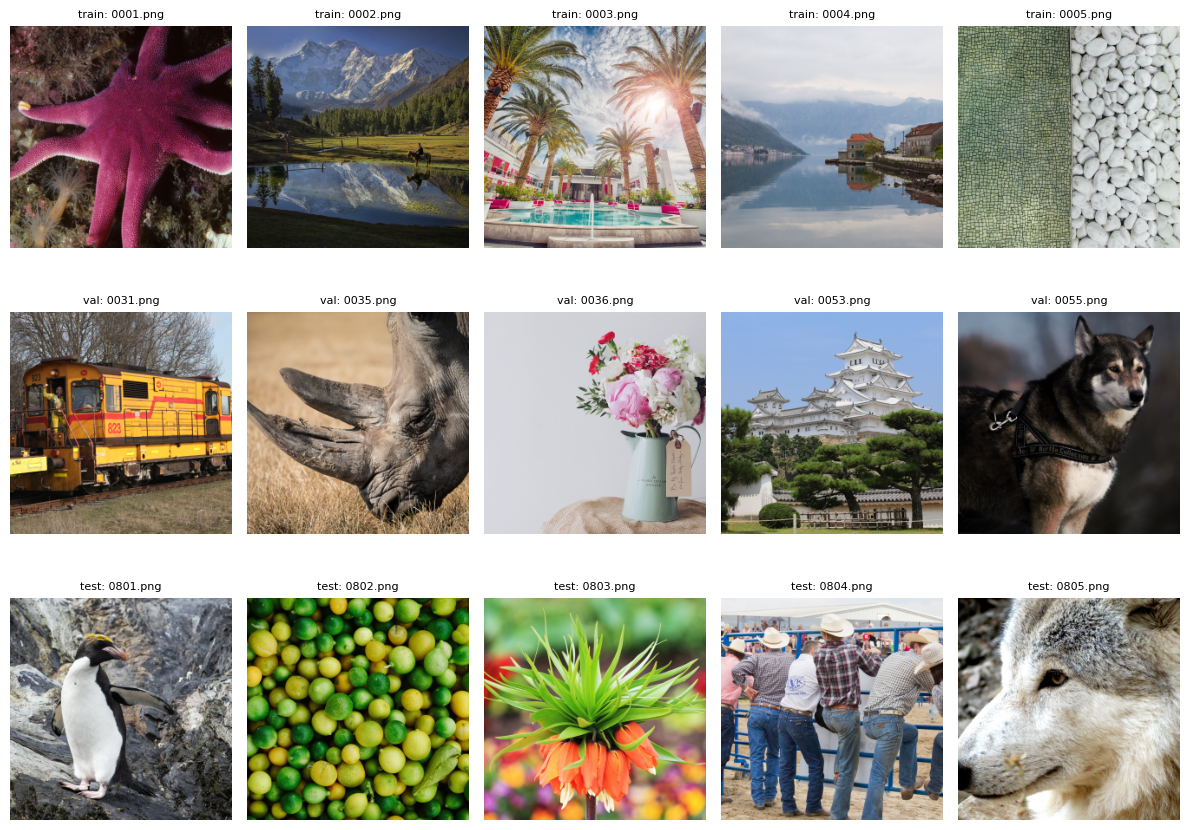

In [16]:
fig, axes = plt.subplots(3, 5, figsize=(12, 9))

for row, folder in enumerate(['train', 'val', 'test']):
    files = sorted(glob.glob(f'{output}/{folder}/*.png'))
    for col in range(5):
        img = cv2.cvtColor(cv2.imread(files[col]), cv2.COLOR_BGR2RGB)
        axes[row, col].imshow(img)
        axes[row, col].set_title(f'{folder}: {files[col].split("/")[-1]}', fontsize=8)
        axes[row, col].axis('off')

plt.tight_layout()
plt.show()